# Task 1 — Zomato Restaurant & Review Analysis

Add the official restaurant/review CSV or Excel file to `data/raw/`. Rename it to include `zomato` for automatic discovery. Verify column meanings before drawing conclusions.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
DATA = ROOT / "data" / "raw"
files = list(DATA.glob("*.csv")) + list(DATA.glob("*.xlsx")) + list(DATA.glob("*.json"))
print("Data files found:", [f.name for f in files])
print("Put the correct task dataset in data/raw/ before interpreting results.")

def load_data(keywords):
    matches = [f for f in files if any(k in f.name.lower() for k in keywords)]
    if not matches:
        print("DATASET MISSING for:", keywords)
        return None
    f = matches[0]
    print("Loading:", f.name)
    if f.suffix.lower() == ".csv":
        return pd.read_csv(f)
    if f.suffix.lower() == ".xlsx":
        return pd.read_excel(f)
    return pd.read_json(f)

def overview(df):
    if df is None:
        return
    print("Shape:", df.shape)
    display(df.head())
    display(df.isna().sum().sort_values(ascending=False).head(20).to_frame("missing"))
    display(df.describe(include="all").T)

df = load_data(['zomato', 'restaurant', 'review'])
overview(df)

Data files found: ['zomato.csv', 'loan_approval_dataset.csv', 'instagram_analytics.csv', 'business_sales_customers.csv']
Put the correct task dataset in data/raw/ before interpreting results.
Loading: zomato.csv
Shape: (9551, 21)


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


,missing
Cuisines,9
Restaurant Name,0
Country Code,0
City,0
Restaurant ID,0
Address,0
Locality,0
Longitude,0
Locality Verbose,0
Latitude,0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Restaurant ID,9551.0,NaN,NaN,NaN,9051128.349178,8791521.282104,53.0,301962.5,6004089.0,18352291.5,18500652.0
Restaurant Name,9551,7446,Cafe Coffee Day,83,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country Code,9551.0,NaN,NaN,NaN,18.365616,56.750546,1.0,1.0,1.0,1.0,216.0
City,9551,141,New Delhi,5473,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Address,9551,8918,"Dilli Haat, INA, New Delhi",11,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Locality,9551,1208,Connaught Place,122,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Locality Verbose,9551,1265,"Connaught Place, New Delhi",122,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Longitude,9551.0,NaN,NaN,NaN,64.126574,41.467058,-157.948486,77.081343,77.191964,77.282006,174.832089
Latitude,9551.0,NaN,NaN,NaN,25.854381,11.007935,-41.330428,28.478713,28.570469,28.642758,55.97698
Cuisines,9542,1825,North Indian,936,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Data quality and restaurant patterns

Duplicate rows: 0
Columns: ['Restaurant ID', 'Restaurant Name', 'Country Code', 'City', 'Address', 'Locality', 'Locality Verbose', 'Longitude', 'Latitude', 'Cuisines', 'Average Cost for two', 'Currency', 'Has Table booking', 'Has Online delivery', 'Is delivering now', 'Switch to order menu', 'Price range', 'Aggregate rating', 'Rating color', 'Rating text', 'Votes']


,Restaurant ID,Country Code,Longitude,Latitude,Average Cost for two,Price range,Aggregate rating,Votes
Restaurant ID,1.000000,0.148471,-0.226081,-0.052081,-0.001693,-0.134540,-0.326212,-0.147023
Country Code,0.148471,1.000000,-0.698299,0.019792,0.043225,0.243327,0.282189,0.154530
Longitude,-0.226081,-0.698299,1.000000,0.043207,0.045891,-0.078939,-0.116818,-0.085101
Latitude,-0.052081,0.019792,0.043207,1.000000,-0.111088,-0.166688,0.000516,-0.022962
Average Cost for two,-0.001693,0.043225,0.045891,-0.111088,1.000000,0.075083,0.051792,0.067783
Price range,-0.134540,0.243327,-0.078939,-0.166688,0.075083,1.000000,0.437944,0.309444
Aggregate rating,-0.326212,0.282189,-0.116818,0.000516,0.051792,0.437944,1.000000,0.313691
Votes,-0.147023,0.154530,-0.085101,-0.022962,0.067783,0.309444,0.313691,1.000000


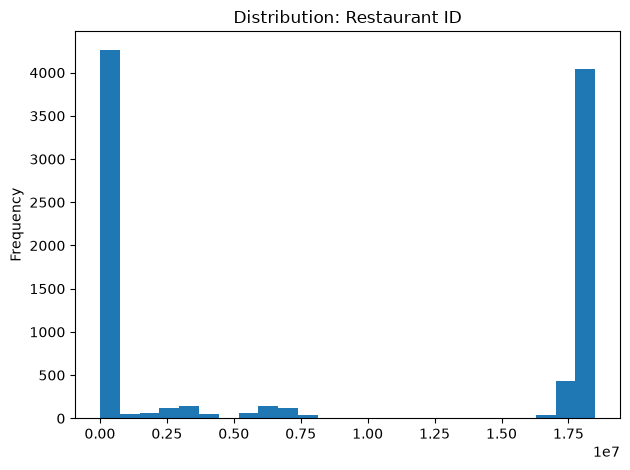


Top values: Restaurant Name


/tmp/ipykernel_18495/3050666726.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cats = df.select_dtypes(include=["object", "category"]).columns


Restaurant Name
Cafe Coffee Day     83
Domino's Pizza      79
Subway              63
Green Chick Chop    51
McDonald's          48
Keventers           34
Pizza Hut           30
Giani               29
Baskin Robbins      28
Barbeque Nation     26
Name: count, dtype: int64


Top values: City


City
New Delhi       5473
Gurgaon         1118
Noida           1080
Faridabad        251
Ghaziabad         25
Ahmedabad         21
Amritsar          21
Bhubaneshwar      21
Guwahati          21
Lucknow           21
Name: count, dtype: int64


Top values: Address


Address
Dilli Haat, INA, New Delhi                                                    11
Sector 41, Noida                                                              11
Greater Kailash (GK) 1, New Delhi                                             10
The Imperial, Janpath, New Delhi                                               9
Cyber Hub, DLF Cyber City, Gurgaon                                             8
HUDA Market, Sector 56, Gurgaon                                                8
Palate of Delhi, Dhaula Kuan Metro Station, Chanakyapuri, New Delhi            8
The Lalit, Barakhamba Avenue, Barakhamba Road, New Delhi                       8
Food Court, 3rd Floor, Logix City Centre, Sector 32, Near Sector 34, Noida     8
DLF Phase 1, Gurgaon                                                           7
Name: count, dtype: int64

Use verified column names to analyze ratings, price, cuisine, votes and reviews.


In [2]:
if df is not None:
    print("Duplicate rows:", df.duplicated().sum())
    print("Columns:", list(df.columns))
    numeric = df.select_dtypes(include="number")
    if not numeric.empty:
        display(numeric.corr(numeric_only=True))
        col = numeric.columns[0]
        ax = numeric[col].dropna().plot(kind="hist", bins=25, title=f"Distribution: {col}")
        plt.tight_layout()
        plt.show()
    cats = df.select_dtypes(include=["object", "category"]).columns
    for col in list(cats)[:3]:
        print("\nTop values:", col)
        display(df[col].value_counts(dropna=False).head(10))
    print("Use verified column names to analyze ratings, price, cuisine, votes and reviews.")
else:
    print("Add the task dataset, rerun this notebook, and document findings from its actual output.")

## Recommendations

Write five evidence-based recommendations after reviewing the real tables and charts. Do not claim business findings until the dataset has been analyzed.